# Task 3: Customer Churn Prediction (Random Forest vs XGBoost)

**Goal:** predict which telecom customers will leave (churn), handle the class imbalance, train Random Forest and XGBoost, and reach a ROC-AUC above 0.80.

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns). About 26% of customers churn, so the classes are imbalanced.

**Plan:** clean `TotalCharges`, one-hot encode categories, balance with SMOTE (Random Forest) and `scale_pos_weight` (XGBoost), cross-validate, then compare ROC-AUC, confusion matrices and feature importances.

**Install once:** `pip install xgboost imbalanced-learn scikit-learn pandas seaborn matplotlib`

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
# Put the CSV from the task page in the same folder as this notebook and set the file name here.
CSV_PATH = "telco_churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    df = pd.read_csv(URL)

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Clean the data

`TotalCharges` is stored as text because a few new customers have a blank value. We convert it to numbers (blanks become `NaN`) and impute them later inside the pipeline.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Null TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head())

df = df.drop(columns="customerID")                 # an ID carries no signal
df["Churn"] = (df["Churn"] == "Yes").astype(int)   # 1 = churned, 0 = stayed
print("\nDuplicate rows:", df.duplicated().sum())

Null TotalCharges: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN

Duplicate rows: 22


## 4. Class imbalance and exploration

Churn
0    5174
1    1869
Name: count, dtype: int64 
Churn rate: 26.5 %


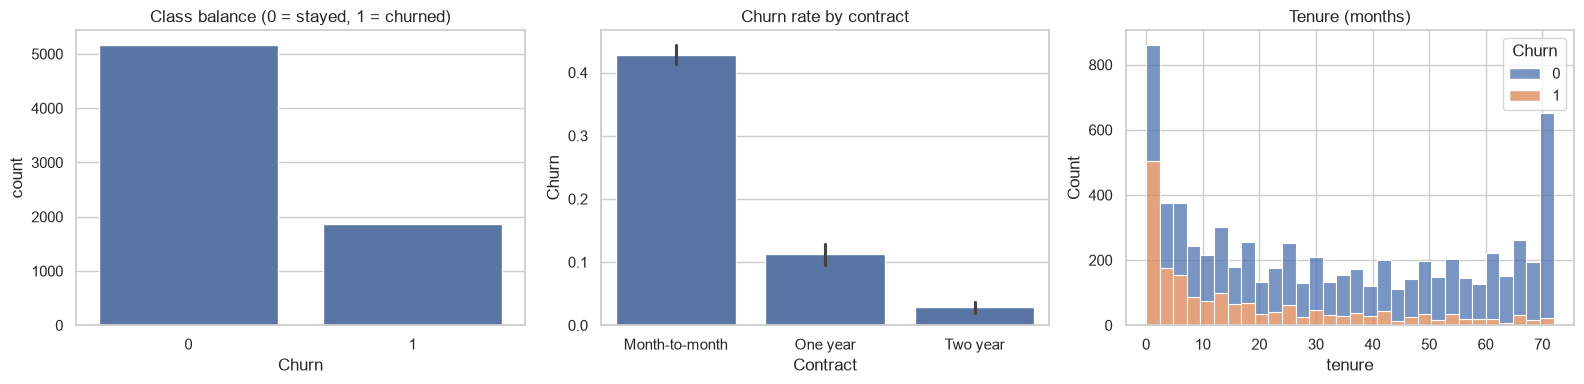

In [4]:
counts = df["Churn"].value_counts()
print(counts, "\nChurn rate:", round(df["Churn"].mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Churn", data=df, ax=axes[0]); axes[0].set_title("Class balance (0 = stayed, 1 = churned)")
sns.barplot(x="Contract", y="Churn", data=df, ax=axes[1]); axes[1].set_title("Churn rate by contract")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[2], multiple="stack"); axes[2].set_title("Tenure (months)")
plt.tight_layout(); plt.show()

## 5. Train/test split (stratified 80/20)

`stratify=y` keeps the churn rate the same in both parts.

In [5]:
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train / test: 0.265 / 0.265


## 6. Preprocessing (OneHotEncoder)

- Text columns are one-hot encoded.
- Numeric columns are median-imputed (this fills the blank `TotalCharges`).
- No scaling is needed because tree models do not care about feature scale.

In [6]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()
print("Categorical:", len(cat_cols), "| Numeric:", num_cols)

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", SimpleImputer(strategy="median"), num_cols),
    ])

Categorical: 15 | Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\sarav\AppData\Local\Temp\ipykernel_12992\2944599571.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()
C:\Users\sarav\AppData\Local\Temp\ipykernel_12992\2944599571.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_gui

## 7. Three models

1. **Random Forest, no balancing** (baseline, to see the effect of imbalance).
2. **Random Forest + SMOTE.** SMOTE creates synthetic minority (churn) examples. It sits inside the pipeline, so it only touches training data, and inside each CV fold. The test set is never resampled.
3. **XGBoost + `scale_pos_weight`.** This tells XGBoost that one churner counts as much as `neg / pos` stayers (class weighting instead of resampling).

In [7]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print("scale_pos_weight =", round(spw, 2))

models = {
    "RF (no balancing)": ImbPipeline([
        ("prep", make_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    "RF + SMOTE": ImbPipeline([
        ("prep", make_preprocessor()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    "XGBoost (scale_pos_weight)": ImbPipeline([
        ("prep", make_preprocessor()),
        ("model", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                subsample=0.8, colsample_bytree=0.8,
                                scale_pos_weight=spw, eval_metric="logloss",
                                random_state=RANDOM_STATE, n_jobs=-1))]),
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print("trained:", name)

scale_pos_weight = 2.77
trained: RF (no balancing)
trained: RF + SMOTE
trained: XGBoost (scale_pos_weight)


## 8. 5-fold cross-validation (ROC-AUC)

One split can be lucky, so we repeat the test 5 times on different folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append({"Model": name, "CV AUC mean": scores.mean(), "CV AUC std": scores.std()})
pd.DataFrame(cv_rows).set_index("Model").round(4)

,CV AUC mean,CV AUC std
Model,,
RF (no balancing),0.8414,0.0092
RF + SMOTE,0.8386,0.0101
XGBoost (scale_pos_weight),0.8444,0.0103


## 9. Test-set results

In [9]:
rows = []
probas = {}
for name, pipe in models.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    probas[name] = proba
    rep = classification_report(y_test, pred, output_dict=True)
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "Accuracy": rep["accuracy"],
                 "Churn precision": rep["1"]["precision"],
                 "Churn recall": rep["1"]["recall"],
                 "Churn F1": rep["1"]["f1-score"]})
results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,ROC-AUC,Accuracy,Churn precision,Churn recall,Churn F1
Model,,,,,
RF (no balancing),0.8383,0.7949,0.6451,0.5053,0.5667
RF + SMOTE,0.8343,0.7864,0.6070,0.5535,0.5790
XGBoost (scale_pos_weight),0.8405,0.7559,0.5274,0.7727,0.6269


Accuracy alone is misleading with 74% / 26% classes: a model that says "nobody churns" would score 74%. **Recall on the churn class** (how many real churners we catch) and **ROC-AUC** tell the real story.

## 10. ROC curves

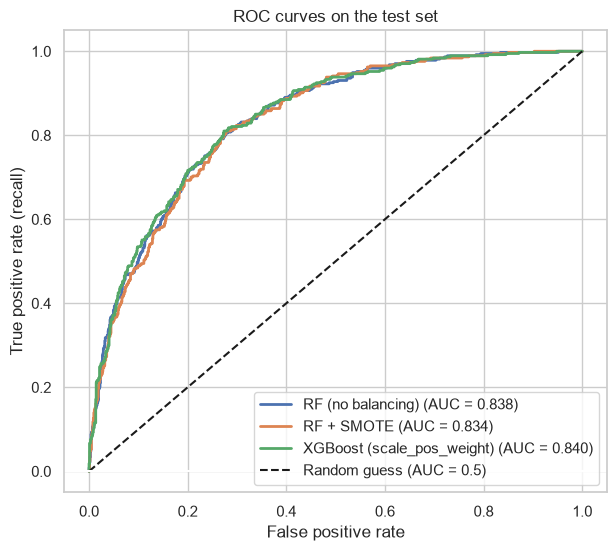

In [10]:
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.axhline(0, color="white")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right")
plt.show()

## 11. Confusion matrices

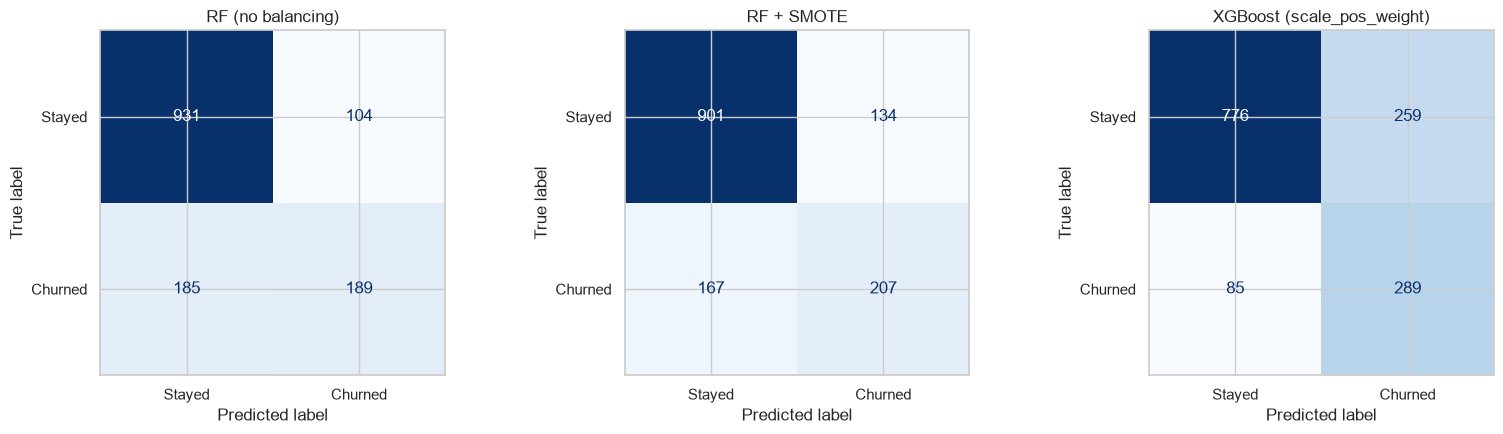

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, proba) in zip(axes, probas.items()):
    pred = (proba >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 12. Top 10 most influential features

Best model by ROC-AUC: XGBoost (scale_pos_weight)


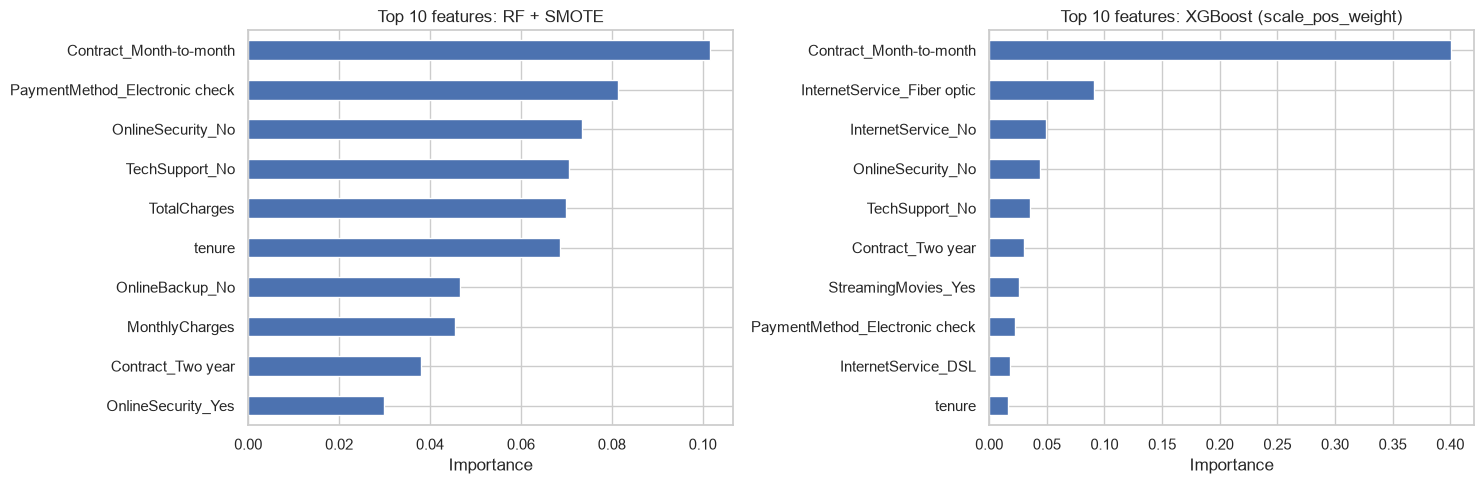

In [12]:
best_name = results["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best_name)

def top_features(pipe, n=10):
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [x.split("__", 1)[1] for x in names]
    imp = pipe.named_steps["model"].feature_importances_
    return pd.Series(imp, index=names).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ["RF + SMOTE", "XGBoost (scale_pos_weight)"]):
    top = top_features(models[name])
    top[::-1].plot(kind="barh", ax=ax)
    ax.set_title(f"Top 10 features: {name}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 13. Conclusions

- **ROC-AUC target:** Every model beat 0.80. On the test set the AUCs were RF (no balancing) 0.838, RF + SMOTE 0.834 and XGBoost 0.840. XGBoost was best.
- **Effect of imbalance:** Only about 26% of customers churn, so the plain Random Forest caught just 189 of 374 churners (recall about 0.51). SMOTE raised recall to about 0.55 (207 of 374). XGBoost with scale_pos_weight raised it to about 0.77 (289 of 374). The price is precision, which fell from about 0.65 to about 0.53, and accuracy, which fell from about 0.80 to 0.76. For churn this trade is worth it, because missing a customer who leaves costs more than contacting one who would have stayed.
- **RF vs XGBoost:** The AUCs are very close (0.838 / 0.834 / 0.840). The 5-fold CV agrees (0.841 / 0.839 / 0.844, std about 0.01), so the difference between models is within the noise. The real difference is in recall at the 0.5 threshold, not in ranking ability.
- **Top features:** Month-to-month contract is the top feature in both models. OnlineSecurity_No, TechSupport_No, Contract_Two year, tenure and PaymentMethod_Electronic check also appear in both top-10 charts. XGBoost additionally highlights fibre-optic internet.
- **Business meaning:** Customers on month-to-month contracts, without online security or tech support, paying by electronic check and with short tenure are the most likely to leave. A retention offer such as a discounted annual contract or a free security/support add-on could target them.
- **Limitation:** SMOTE on one-hot columns creates fractional values, the 0.5 decision threshold could be tuned to trade precision for recall, and feature importance shows association, not cause.